# Lab 4, Day 1 — Regression on California Housing

Build an MLP regressor in PyTorch, then compare it head-to-head against your own Lab 2
NumPy gradient descent code on the exact same data. See `Lab4_Day1_Instructions.md`
for the full walkthrough.

This notebook is just a shell: it gives you a place to call and plot your functions,
but the loading, model, training loop, and comparison are yours to write.

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt


## Step 1: Load and preprocess (`stage_a_regression.py`)

In [13]:
# TODO: load California Housing, split train/test, fit_transform the scaler on
# train only, transform test, reshape targets to (n, 1)
from sklearn.datasets import fetch_california_housing
from stage_a_regression import load_california_housing

data, X_train, X_test, y_train, y_test = load_california_housing()


In [14]:
california_housing = fetch_california_housing(as_frame=True)
print(california_housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [15]:
california_housing.frame.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Step 2-3: Model, loss, optimizer, training loop

In [16]:
# TODO: build_mlp from train.py (or write it directly), train with train_full_batch,
# store loss.item() each epoch - not the tensor itself
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim):
        super().__init__()      # mandatory to call the parent constructor - forgetting this breaks everything
        self.fc1 = nn.Linear(in_dim, hidden)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden, out_dim)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        return self.fc2(x)


model = MLP(8, 32, 1)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)
print(model)

MLP(
  (fc1): Linear(in_features=8, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [17]:
from train import train_model

losses = train_model(
    model,
    X_train,
    y_train,
    criterion,
    optimizer,
    epochs=200
)

torch.save(model.state_dict(), "stage_a.pt")

## Step 4: Evaluate and plot

In [18]:
# TODO: model.eval() + torch.no_grad() to get test MSE; plot the training loss curve

model.eval()

with torch.no_grad():
    y_pred = model(X_test)
    mlp_test_mse = criterion(y_pred, y_test).item()

print("Test MSE:", mlp_test_mse)

Test MSE: 0.3912056088447571


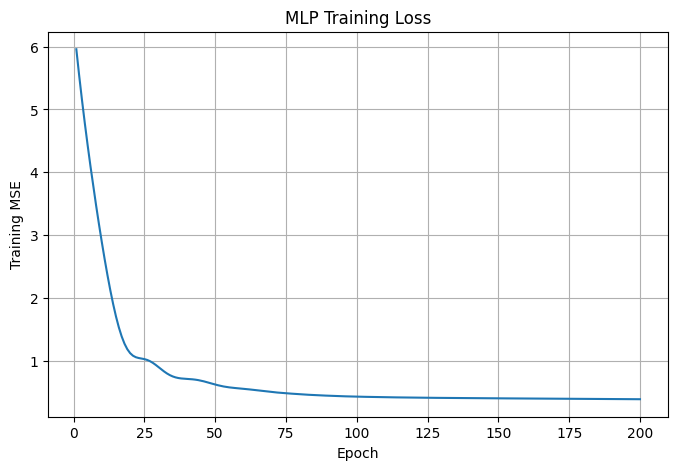

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, len(losses) + 1), losses)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("MLP Training Loss")
plt.grid(True)
plt.show()


In [20]:
model.load_state_dict(torch.load("stage_a.pt", weights_only=True))
model.eval()

with torch.no_grad():
    prediction = model(X_test[0].unsqueeze(0))

print("Prediction:", prediction.item())
print("Actual:", y_test[0].item())

Prediction: 1.797323226928711
Actual: 1.36899995803833


## Step 5: Compare against your Lab 2 NumPy code

In [21]:
# TODO: fit a linear model on the same preprocessed data using your own hand-derived
# gradient descent, compare test MSE against the MLP, plot both curves side by side

import numpy as np

def f(X, y, w, b):
    return np.mean((X @ w + b - y) ** 2)

def grad_f(X, y, w, b):
    n = X.shape[0]
    error = X @ w + b - y
    return (2 / n) * X.T @ error, (2 / n) * np.sum(error)

def gradient_descent(start_w, start_b, X, y, lr, steps):
    history = []
    w = start_w
    b = start_b

    for step in range(0, steps):
        grad_w, grad_b = grad_f(X, y, w, b)

        w = w - lr * grad_w
        b = b - lr * grad_b

        history.append(f(X, y, w, b))

    return w, b, np.array(history)

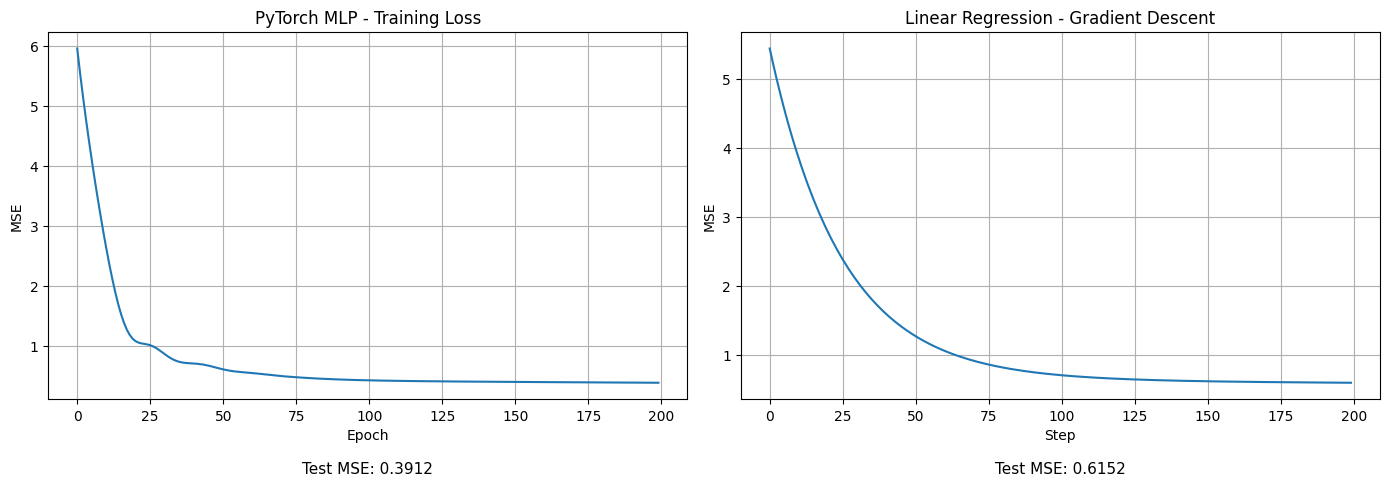

In [22]:
X_train_np = X_train.numpy()
y_train_np = y_train.numpy()

X_test_np = X_test.numpy()
y_test_np = y_test.numpy()

w = np.zeros((X_train_np.shape[1], 1))
b = 0.0

w, b, history = gradient_descent(
    w, b, X_train_np, y_train_np, 0.01, 200
)

y_pred = X_test_np @ w + b

linear_test_mse = np.mean((y_pred - y_test_np) ** 2)

# Plot MLP and Gradient Descent side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PyTorch MLP
axes[0].plot(losses)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].set_title("PyTorch MLP - Training Loss")
axes[0].grid(True)
axes[0].text(
    0.5, -0.20,
    f"Test MSE: {mlp_test_mse:.4f}",
    transform=axes[0].transAxes,
    ha="center",
    fontsize=11
)

# NumPy Gradient Descent
axes[1].plot(history)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("MSE")
axes[1].set_title("Linear Regression - Gradient Descent")
axes[1].grid(True)
axes[1].text(
    0.5, -0.20,
    f"Test MSE: {linear_test_mse:.4f}",
    transform=axes[1].transAxes,
    ha="center",
    fontsize=11
)

plt.tight_layout()
plt.show()

### Written prompt

> **Your MLP barely beats the linear model, and might lose to it. What would have to be
> true about this data for the MLP to win decisively — and what does that tell you about
> when a neural network is the right tool?**

For the MLP to clearly outperform the linear model, the data would need to contain strong non-linear relationships or important interactions between features. If the relationship is mostly linear, the extra complexity of a neural network may not provide much benefit and could even lead to overfitting. This shows that neural networks are most useful when the problem contains complex patterns that simpler models cannot capture.

---
**Before you close this notebook today:** save your trained model
(`torch.save(model.state_dict(), "stage_a.pt")`), and run the Fashion-MNIST loader
once (see `Lab4_Day2_Instructions.md` Step 1) so it's cached before Day 2. Keep this
notebook - Day 2 is a new notebook in the same folder.